# Sales & Customer Analysis: Online Retail II
Notebook ini membaca hasil query SQL dan menampilkan jawaban Q1-Q14. Semua angka berasal dari `project/results/`. Jalankan `01` sampai `08` lebih dulu jika folder hasil kosong.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
R = '../2-analysis/'  # relatif terhadap results/3-presentation
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

## Q1 Tren revenue dan musim
Revenue naik turun setiap tahun. Rata-rata per bulan dipakai untuk menguji musim.

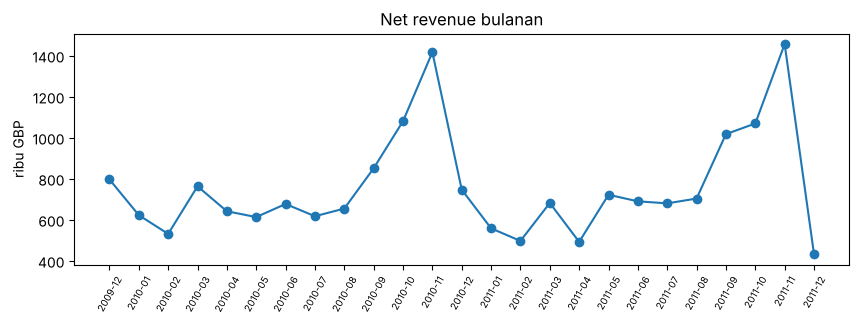

,bulan_ke,rata_rata_revenue,jumlah_tahun
0,1,"590,464.03",2
1,2,"514,145.89",2
2,3,"722,630.61",2
3,4,"566,944.45",2
4,5,"667,682.41",2
5,6,"683,525.55",2
6,7,"648,761.24",2
7,8,"679,142.49",2
8,9,"934,351.32",2
9,10,"1,074,989.86",2


In [2]:
m = pd.read_csv(R + 'q1_monthly.csv')
plt.figure(figsize=(10, 3)); plt.plot(m['bulan'], m['net_revenue']/1e3, marker='o'); plt.xticks(rotation=60, fontsize=7); plt.ylabel('ribu GBP'); plt.title('Net revenue bulanan'); plt.show()
pd.read_csv(R + 'q1_season.csv')

## Q2 Negara di luar Inggris
Negara lain menyumbang sebagian kecil revenue.

In [3]:
c = pd.read_csv(R + 'q2_country.csv')
c.head(11)

,country,net_revenue,share_total,orders
0,United Kingdom,"16,144,736.46",0.85,36535
1,EIRE,"609,953.78",0.03,626
2,Netherlands,"548,330.70",0.03,228
3,Germany,"411,959.16",0.02,789
4,France,"321,733.39",0.02,622
5,Australia,"166,444.42",0.01,95
6,Switzerland,"99,403.06",0.01,93
7,Spain,"91,013.44",0.00,154
8,Sweden,"87,775.52",0.00,105
9,Denmark,"64,459.59",0.00,43


## Q4 Pareto produk
Jumlah produk yang mencapai 80% revenue dibandingkan total produk.

In [4]:
p = pd.read_csv(R + 'q4_pareto_product.csv')
n80 = int((p['cum_share'] < 0.8).sum() + 1)
print(f'{n80:,} dari {len(p):,} produk mencapai 80% revenue')

1,048 dari 4,858 produk mencapai 80% revenue


## Q6-Q8 Pelanggan, segmen, dan repeat purchase

In [5]:
pd.read_csv(R + 'q6_top10.csv')


,pelanggan_total,pelanggan_top10,revenue_total,revenue_top10,share_top10
0,5939,594,"16,289,991.27","10,375,572.10",0.64


In [6]:
pd.read_csv(R + 'q7_segments.csv')

,segment,pelanggan,revenue_total,median_revenue,repeat_customers,share_revenue,repeat_rate
0,VIP,426,"8,876,146.53","10,134.69",423,0.54,0.99
1,Loyal,851,"3,317,036.40","3,354.95",835,0.20,0.98
2,Regular,1276,"1,966,870.23","1,195.64",1161,0.12,0.91
3,Light,1701,"1,063,987.57",397.52,1118,0.07,0.66
4,Tidak aktif 12 bulan,1685,"1,065,950.54",323.25,718,0.07,0.43


In [7]:
pd.read_csv(R + 'q8_repeat_segment.csv')

,segment,pelanggan,repeat,repeat_rate
0,VIP,426,423,0.99
1,Loyal,851,835,0.98
2,Regular,1276,1161,0.91
3,Light,1701,1118,0.66
4,Tidak aktif 12 bulan,1624,718,0.44


## Q10 Skenario retensi (estimated)
Tambahan revenue jika repeat purchase rate naik. Ini estimasi, bukan hasil eksperimen.

In [8]:
pd.read_csv(R + 'q10_retention_scenarios.csv')

,segmen,pelanggan_segmen,kenaikan_poin,pelanggan_baru_kembali,revenue_per_pelanggan_kembali_per_tahun,tambahan_revenue_per_tahun_estimated
0,VIP,426,3,12.80,"10,369.94","132,528.00"
1,VIP,426,5,21.30,"10,369.94","220,880.00"
2,VIP,426,10,42.60,"10,369.94","441,760.00"
3,Loyal,851,3,25.50,"1,948.78","49,752.00"
4,Loyal,851,5,42.50,"1,948.78","82,921.00"
5,Loyal,851,10,85.10,"1,948.78","165,841.00"
6,Regular,1276,3,38.30,803.39,"30,754.00"
7,Regular,1276,5,63.80,803.39,"51,257.00"
8,Regular,1276,10,127.60,803.39,"102,513.00"
9,Light,1701,3,51.00,414.47,"21,150.00"


## Q12-Q14 Validitas data
Ringkasan pembersihan dan cek silang.

In [9]:
pd.read_csv('../1-data-preparation/01_cleaning_log.csv')

,langkah,status,baris,revenue,catatan
0,baris mentah (dua sheet),total,1067371,0.00,NaN
1,duplikat persis (8 kolom),dibuang,34335,"431,716.87",dari sheet lain (periode overlap Dec 2010): 22...
2,harga nol atau negatif,dibuang,6019,"-158,676.14",tidak bisa dipakai untuk revenue
3,baris batal (invoice diawali C),dicatat,19104,"-1,462,050.61","tetap dihitung, mengurangi revenue bersih"
4,baris tanpa Customer ID,dicatat,229202,"2,724,218.55","tetap dihitung di revenue, tidak dipakai anali..."
5,"kode non-produk (biaya, ongkir, adjustment)",dicatat,5889,"87,943.64","tetap dihitung di revenue, tidak dipakai anali..."
6,baris tanpa deskripsi,dicatat,0,0.00,"tetap dipakai, deskripsi dibiarkan kosong"
7,baris bersih (dimuat ke database),total,1027017,"19,014,209.82",net revenue setelah cleaning


In [10]:
pd.read_csv(R + 'q12_impact.csv')

,ukuran,nilai
0,revenue mentah (sebelum cleaning),"19,287,250.55"
1,revenue setelah cleaning (net),"19,014,209.82"
2,revenue penjualan (tanpa batal),"20,476,260.43"
3,revenue batal (negatif),"-1,462,050.61"
4,selisih revenue mentah vs net,"273,040.73"


In [11]:
pd.read_csv(R + '04_crosscheck_sql_pandas.csv')

,level,dibandingkan,sama,selisih_maks,status
0,net revenue per bulan,25,25,0.00,PASS
1,net revenue per negara,43,43,0.00,PASS
2,net revenue per produk,4891,4891,0.00,PASS
3,jumlah pelanggan,1,1,0.00,PASS
4,total revenue pelanggan,1,1,0.00,PASS
5,"KPI total (net revenue, orders)",2,2,0.00,PASS


In [12]:
pd.read_csv(R + '05_crosscheck_spreadsheet.csv')

,level,dibandingkan,sama,selisih_maks,status
0,net revenue per bulan (LibreOffice),25,25,0.00,PASS
1,net revenue per negara (LibreOffice),43,43,0.00,PASS


## Hipotesis
Verdict mengikuti aturan di `docs/definitions.md`.

In [13]:
pd.read_csv(R + '03_hypothesis_tests.csv')

,no,hipotesis,verdict,bukti
0,H1,Penjualan memuncak September sampai November,Terbukti,Bulan tertinggi rata-rata: 11. Tiga teratas: [...
1,H2,Sebagian kecil pelanggan menyumbang sebagian b...,Terbukti,10% pelanggan teratas = 63.7% revenue
2,H3,Sebagian kecil produk menyumbang sekitar 80% r...,Sebagian,1048 dari 4858 produk (21.6%) mencapai 80% rev...
3,H4,Pelanggan luar Inggris lebih jarang memesan te...,Sebagian,"Rata-rata invoice per pelanggan: UK 6.20, non-..."
4,H5,Pembelian ulang dalam 90 hari pertama terkait ...,Sebagian,Pelanggan dengan pembelian ulang <= 90 hari: 8...
